# Report statistico 1: i dati e la significatività dei risultati

Questo notebook descrive i dati della competizione (battaglie Pokémon Gen 2 OU, si predice `player_won` dallo stato al turno 30) e misura **quanto è significativo** ciò che vediamo: lo sbilanciamento delle classi, le relazioni tra stato e vittoria, il potere predittivo delle singole feature, lo spostamento tra train e test e infine l'incertezza sull'accuracy dei modelli.

Usa le cache già calcolate (`outputs/features.pkl`, `outputs/oof_mc_rec/`, `outputs/experiments/`): non riaddestra lo stack. Tutti i test sono bilaterali con α = 0.05; quando si testano molte ipotesi insieme si controlla il *false discovery rate* con Benjamini-Hochberg.

In [1]:
import os, sys, json, hashlib, warnings
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import logit
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "reports" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, os.path.join(ROOT, "src"))
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
RNG = np.random.default_rng(0)

def wilson(k, n, z=1.96):
    """Intervallo di Wilson al 95% per una proporzione."""
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def mcnemar(a_ok, b_ok):
    """Test di McNemar esatto su due vettori di correttezza appaiati."""
    b = int((a_ok & ~b_ok).sum()); c = int((~a_ok & b_ok).sum())
    p = stats.binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0
    return b, c, p

def paired_bootstrap(a_ok, b_ok, n=5000):
    """IC al 95% della differenza di accuracy (b - a) ricampionando le battaglie."""
    d = b_ok.astype(float) - a_ok.astype(float)
    idx = RNG.integers(0, len(d), (n, len(d)))
    bs = d[idx].mean(1)
    return d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)

In [2]:
def load_jsonl(p):
    with open(p) as f:
        return [json.loads(l) for l in f]
train = load_jsonl("data/train.jsonl"); test = load_jsonl("data/test.jsonl")
F = pd.read_pickle("outputs/features.pkl")
tr = F[F.is_test == 0].reset_index(drop=True); te = F[F.is_test == 1].reset_index(drop=True)
y = tr.player_won.values.astype(int)
assert (tr.battle_id.values == np.array([b["battle_id"] for b in train])).all()
print(f"train {len(train)} battaglie, test {len(test)}, feature base {F.shape[1] - 3}")

train 10000 battaglie, test 5000, feature base 277


## 1. Bilanciamento delle classi

Se le classi fossero sbilanciate, l'accuracy andrebbe confrontata con la classe maggioritaria e non con 0.5. Test binomiale esatto contro p = 0.5.

In [3]:
k = y.sum(); n = len(y)
lo, hi = wilson(k, n)
print(f"p1 vince {k}/{n} = {k/n:.4f}  IC95% [{lo:.4f}, {hi:.4f}]  binomiale p = {stats.binomtest(k, n, .5).pvalue:.3f}")

p1 vince 5000/10000 = 0.5000  IC95% [0.4902, 0.5098]  binomiale p = 1.000


**Lettura:** le classi sono bilanciate (nessuna differenza significativa da 50%). Il riferimento "a caso" per l'accuracy è quindi 0.50 e la soglia 0.5 delle probabilità non va spostata (lo conferma l'esperimento sulla soglia a mediana, senza effetto).

## 2. Struttura delle battaglie

Lunghezza della timeline, quanti pokemon di p2 sono stati visti, quanti KO per lato al turno 30. Il confronto dei KO tra p1 e p2 è appaiato (stessa battaglia), quindi si usa il test di Wilcoxon per ranghi con segno.

lunghezza timeline: {30: 15000}


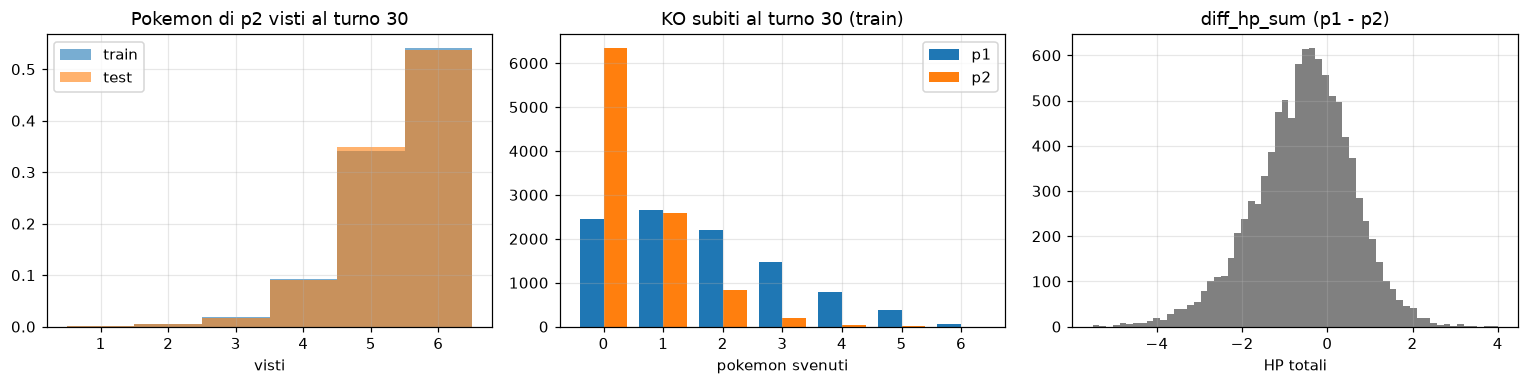

KO medi al turno 30: p1 1.69, p2 0.50; Wilcoxon p = 0.0e+00
ma p1 vince il 50.0%: la differenza di KO al turno 30 da sola non decide la partita


In [4]:
lens = Counter(len(b["battle_timeline"]) for b in train + test)
print("lunghezza timeline:", dict(lens))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for d, lab in ((tr, "train"), (te, "test")):
    ax[0].hist(d.p2_n_seen, bins=np.arange(.5, 7.5), alpha=.6, density=True, label=lab)
ax[0].set(title="Pokemon di p2 visti al turno 30", xlabel="visti"); ax[0].legend()
ax[1].hist([tr.p1_fainted, tr.p2_fainted], bins=np.arange(-.5, 7.5), label=["p1", "p2"])
ax[1].set(title="KO subiti al turno 30 (train)", xlabel="pokemon svenuti"); ax[1].legend()
ax[2].hist(tr.diff_hp_sum, bins=60, color="gray"); ax[2].set(title="diff_hp_sum (p1 - p2)", xlabel="HP totali")
plt.tight_layout(); plt.show()
w = stats.wilcoxon(tr.p1_fainted, tr.p2_fainted)
print(f"KO medi al turno 30: p1 {tr.p1_fainted.mean():.2f}, p2 {tr.p2_fainted.mean():.2f}; Wilcoxon p = {w.pvalue:.1e}")
print(f"ma p1 vince il {y.mean():.1%}: la differenza di KO al turno 30 da sola non decide la partita")

**Lettura:** le timeline hanno sempre 30 turni, quindi la lunghezza non rivela l'esito. p1 subisce molti più KO di p2 nei primi 30 turni (differenza altamente significativa) eppure vince metà delle partite: le dinamiche dopo il turno 30 sono diverse da quelle osservabili, ed è questo il limite strutturale del problema.

## 3. Duplicati e pool di team

Battaglie con timeline identica e quanto sono ripetuti i team. Queste proprietà condizionano la validazione (i duplicati vanno tenuti nello stesso fold) e giustificano l'inferenza dei team nascosti di p2.

gruppi duplicati: 27 {'train-train': 17, 'test-train': 8, 'test-test': 2}; gruppi con >1 battaglia di train ed etichetta coerente: 17
team p1: 15000 totali, 5607 distinti; il team più frequente compare 280 volte
team p2 visti per intero: 8095, di cui 75.2% compare anche come team p1


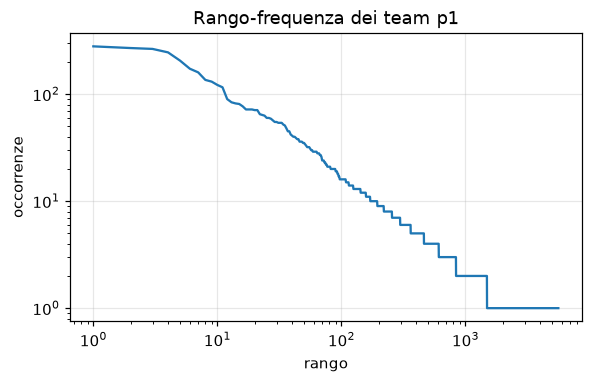

In [5]:
key = lambda b: hashlib.md5(json.dumps(b["battle_timeline"], sort_keys=True).encode()).hexdigest()
groups = {}
for split, bs in (("train", train), ("test", test)):
    for b in bs:
        groups.setdefault(key(b), []).append((split, b.get("player_won")))
dup = [g for g in groups.values() if len(g) > 1]
kinds = Counter("-".join(sorted(s for s, _ in g)) for g in dup)
consistent = sum(len({w for s, w in g if s == "train"}) == 1 for g in dup if sum(s == "train" for s, _ in g) > 1)
print(f"gruppi duplicati: {len(dup)} {dict(kinds)}; gruppi con >1 battaglia di train ed etichetta coerente: {consistent}")

teams = Counter(frozenset(p["name"] for p in b["p1_team_details"]) for b in train + test)
p2_full = []
for b in train + test:
    seen = []
    for t in b["battle_timeline"]:
        n_ = t["p2_pokemon_state"]["name"]
        if n_ not in seen: seen.append(n_)
    if len(seen) == 6: p2_full.append(frozenset(seen))
in_pool = np.mean([t in teams for t in p2_full])
print(f"team p1: {sum(teams.values())} totali, {len(teams)} distinti; il team più frequente compare {teams.most_common(1)[0][1]} volte")
print(f"team p2 visti per intero: {len(p2_full)}, di cui {in_pool:.1%} compare anche come team p1")
freq = np.sort(np.array(list(teams.values())))[::-1]
plt.figure(figsize=(6, 3.4)); plt.loglog(np.arange(1, len(freq) + 1), freq)
plt.title("Rango-frequenza dei team p1"); plt.xlabel("rango"); plt.ylabel("occorrenze"); plt.show()

**Lettura:** i team non sono indipendenti: vengono da un pool ricorrente con una coda lunga (rango-frequenza quasi lineare in scala log-log). Per questo ricostruire i pokemon nascosti di p2 per team interi funziona meglio delle co-occorrenze a coppie. I pochi duplicati hanno sempre etichetta coerente; quelli tra train e test permettono di copiare l'etichetta in 7 battaglie di test.

## 4. Relazione tra stato al turno 30 e vittoria

Probabilità di vittoria di p1 per fasce delle due variabili più informative, con intervalli di Wilson. Test χ² di indipendenza tra fascia e vittoria, e V di Cramér come misura dell'effetto.

diff_hp_sum: chi2 = 1396, dof = 9, p = 5.4e-295, V di Cramér = 0.374
diff_fainted: chi2 = 637, dof = 6, p = 2.0e-134, V di Cramér = 0.253


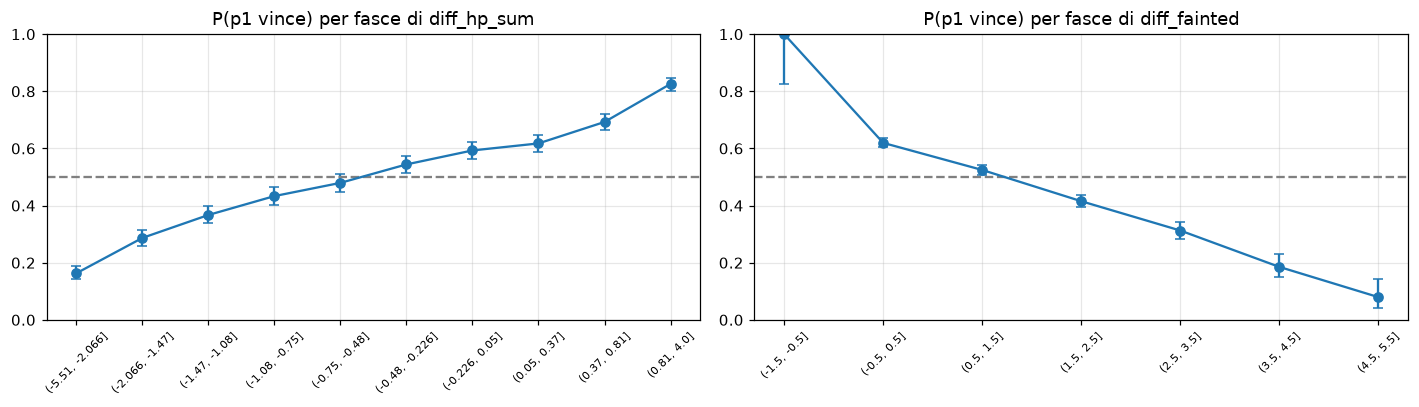

In [6]:
def winrate_table(x, bins, name):
    cut = pd.cut(x, bins)
    t = pd.DataFrame({"bin": cut, "y": y}).groupby("bin", observed=True).y.agg(["sum", "count"])
    t["win"] = t["sum"] / t["count"]
    t[["lo", "hi"]] = [wilson(s, c) for s, c in zip(t["sum"], t["count"])]
    ct = pd.crosstab(cut, y)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f"{name}: chi2 = {chi2:.0f}, dof = {dof}, p = {p:.1e}, V di Cramér = {v:.3f}")
    return t

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, (col, bins) in zip(ax, (("diff_hp_sum", np.quantile(tr.diff_hp_sum, np.linspace(0, 1, 11))),
                                ("diff_fainted", np.arange(-6.5, 6.5)))):
    t = winrate_table(tr[col], np.unique(bins), col)
    mid = np.arange(len(t))
    a.errorbar(mid, t.win, yerr=[t.win - t.lo, t.hi - t.win], fmt="o-", capsize=3)
    a.axhline(.5, color="gray", ls="--"); a.set_xticks(mid); a.set_xticklabels([str(i) for i in t.index], rotation=45, fontsize=7)
    a.set(title=f"P(p1 vince) per fasce di {col}", ylim=(0, 1))
plt.tight_layout(); plt.show()

**Lettura:** la relazione è monotona e molto significativa, ma l'effetto è moderato: anche nelle fasce più estreme la probabilità resta lontana da 0 e 1 per buona parte delle battaglie, e nelle fasce centrali (le più popolate) è vicina a 0.5. Molte partite sono genuinamente in bilico al turno 30.

## 5. Significatività univariata delle feature

Per ognuna delle feature base: AUC rispetto a `player_won` (0.5 = nessun segnale) e test di Mann-Whitney (equivalente a testare AUC = 0.5). Con centinaia di test si corregge con Benjamini-Hochberg (FDR 5%).

In [7]:
num = tr.select_dtypes("number").columns
cols = [c for c in num if c not in ("battle_id", "is_test", "player_won") and tr[c].nunique() > 1]
rows = []
for c in cols:
    x = tr[c].fillna(tr[c].median()).values
    auc = roc_auc_score(y, x)
    p = stats.mannwhitneyu(x[y == 1], x[y == 0]).pvalue
    rows.append((c, auc, abs(auc - .5), p))
U = pd.DataFrame(rows, columns=["feature", "auc", "effetto", "p"])
U["q_bh"] = stats.false_discovery_control(U.p.fillna(1))
U = U.sort_values("effetto", ascending=False).reset_index(drop=True)
sig = (U.q_bh < .05).sum()
print(f"{len(U)} feature testate; significative dopo BH (q < 0.05): {sig} ({sig/len(U):.0%})")
print(f"con effetto |AUC-0.5| >= 0.1: {(U.effetto >= .1).sum()}; >= 0.05: {(U.effetto >= .05).sum()}")
U.head(20).style.format({"auc": "{:.3f}", "effetto": "{:.3f}", "p": "{:.1e}", "q_bh": "{:.1e}"})

269 feature testate; significative dopo BH (q < 0.05): 168 (62%)
con effetto |AUC-0.5| >= 0.1: 36; >= 0.05: 86


,feature,auc,effetto,p,q_bh
0,diff_hp_sum,0.714,0.214,1.2e-301,3.2e-299
1,diff_eff_hp,0.711,0.211,4.3e-293,5.8e-291
2,diff_alive_hpw_bst,0.709,0.209,7.6e-287,6.8e-285
3,hp_diff_slope,0.692,0.192,2.1e-243,1.4e-241
4,hp_diff_t25,0.678,0.178,3.0e-209,1.6e-207
5,hp_diff_min,0.676,0.176,3.2e-205,1.4e-203
6,hp_diff_mean,0.665,0.165,3.7e-179,1.4e-177
7,diff_dmg_dealt,0.662,0.162,3.0e-173,1.0e-171
8,hp_diff_last10_change,0.647,0.147,3.5e-142,1.0e-140
9,hp_diff_t20,0.645,0.145,2.6e-138,7.1e-137


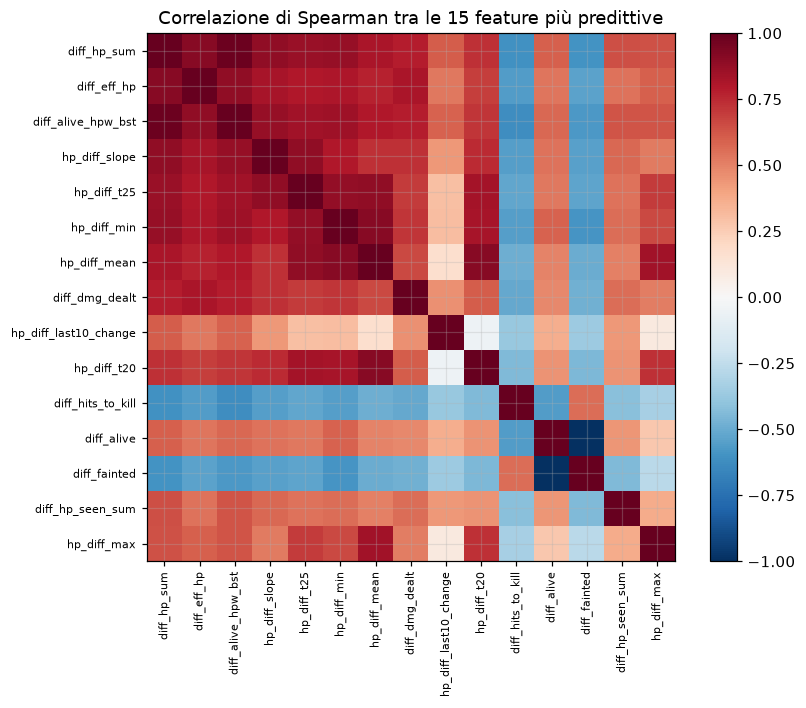

|rho| medio tra le top 15: 0.61; coppie con |rho| > 0.8: 25


In [8]:
top = U.feature.head(15).tolist()
C = tr[top].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(top))); ax.set_xticklabels(top, rotation=90, fontsize=7)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top, fontsize=7)
plt.colorbar(im); ax.set_title("Correlazione di Spearman tra le 15 feature più predittive"); plt.tight_layout(); plt.show()
off = C.values[np.triu_indices(len(top), 1)]
print(f"|rho| medio tra le top 15: {np.abs(off).mean():.2f}; coppie con |rho| > 0.8: {(np.abs(off) > .8).sum()}")

**Lettura:** gran parte delle feature è statisticamente significativa (con 10000 battaglie anche effetti piccoli lo sono), ma solo poche hanno un effetto grande, e le più forti sono fortemente correlate tra loro: misurano quasi tutte "chi è avanti negli HP/KO". Significatività univariata ≠ informazione nuova: è il motivo per cui le feature aggiunte in seguito (matchup, P(KO), storia per pokemon) sono significative da sole ma non migliorano lo stack.

## 6. Train e test vengono dalla stessa distribuzione?

Due verifiche: test di Kolmogorov-Smirnov per feature (con BH) e *adversarial validation*, cioè un classificatore che prova a distinguere le battaglie di train da quelle di test. AUC ≈ 0.5 significa nessuno spostamento sfruttabile.

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
import lightgbm as lgb
ks = pd.DataFrame([(c, *stats.ks_2samp(tr[c].dropna(), te[c].dropna())) for c in cols], columns=["feature", "ks", "p"])
ks["q_bh"] = stats.false_discovery_control(ks.p)
print(f"feature con distribuzione diversa tra train e test (BH q < 0.05): {(ks.q_bh < .05).sum()} su {len(ks)}")
X = pd.concat([tr[cols], te[cols]]).fillna(0).values; z = np.r_[np.zeros(len(tr)), np.ones(len(te))]
pa = cross_val_predict(lgb.LGBMClassifier(n_estimators=300, learning_rate=.03, num_leaves=31, verbose=-1),
                       X, z, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
print(f"adversarial validation: AUC train vs test = {roc_auc_score(z, pa):.3f}")
ks.sort_values("ks", ascending=False).head(5)

feature con distribuzione diversa tra train e test (BH q < 0.05): 0 su 269


adversarial validation: AUC train vs test = 0.501


,feature,ks,p,q_bh
4,p1_team_def_mean,0.032800,0.001523,0.40963
223,active_p1_turns_to_ko,0.026789,0.026359,1.00000
86,hp_diff_mean,0.025400,0.026951,1.00000
216,diff_fast_ohko_frac,0.024800,0.032950,1.00000
175,p2_no_move,0.024500,0.036367,1.00000


**Lettura:** nessuna differenza rilevante tra train e test. La CV sul train è quindi una stima credibile dell'accuratezza sul test (al netto della varianza).

## 7. Quanto si può prevedere? Curva di apprendimento e casi già decisi

Se l'accuracy salisse ancora con più dati, servirebbero modelli più espressivi; se è piatta, il limite è l'informazione contenuta nello stato al turno 30. Curva di apprendimento di un LightGBM sulle feature dense (5-fold, stesse condizioni per ogni dimensione).

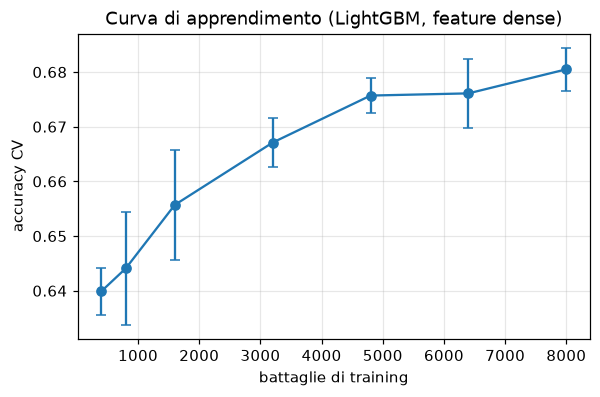

    400  0.6399 ± 0.0043
    800  0.6441 ± 0.0103
   1600  0.6557 ± 0.0100
   3200  0.6671 ± 0.0045
   4800  0.6757 ± 0.0031
   6400  0.6761 ± 0.0063
   8000  0.6805 ± 0.0040
pendenza finale: +0.15 punti di accuracy ogni 1000 battaglie in più
battaglie già finite al turno 30: 63 (0.6%); vincitore ovvio nel 98% dei casi


In [10]:
from sklearn.model_selection import learning_curve
Xd = tr[cols].fillna(0).values
sizes, _, va = learning_curve(lgb.LGBMClassifier(n_estimators=400, learning_rate=.03, num_leaves=15,
                                                 colsample_bytree=.5, verbose=-1, n_jobs=-1),
                              Xd, y, train_sizes=[.05, .1, .2, .4, .6, .8, 1.0],
                              cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring="accuracy")
m, s = va.mean(1), va.std(1)
plt.figure(figsize=(6, 3.6)); plt.errorbar(sizes, m, yerr=s, fmt="o-", capsize=3)
plt.xlabel("battaglie di training"); plt.ylabel("accuracy CV"); plt.title("Curva di apprendimento (LightGBM, feature dense)"); plt.show()
for n_, a, sd in zip(sizes, m, s): print(f"  {n_:5d}  {a:.4f} ± {sd:.4f}")
slope = (m[-1] - m[-3]) / (sizes[-1] - sizes[-3]) * 1000
print(f"pendenza finale: {slope*100:+.2f} punti di accuracy ogni 1000 battaglie in più")

done = (tr.p1_alive == 0) | (tr.p2_fainted == 6)
print(f"battaglie già finite al turno 30: {done.sum()} ({done.mean():.1%}); vincitore ovvio nel "
      f"{((tr.p1_alive[done] > 0).astype(int) == y[done]).mean():.0%} dei casi")

**Lettura:** la curva cresce sempre più lentamente: da 400 a 3200 battaglie guadagna circa 3 punti, da 3200 a 8000 poco più di 1. Con l'intero train la pendenza residua è di circa +0.15 punti ogni 1000 battaglie, e continua a diminuire: anche raddoppiando i dati il guadagno atteso sarebbe al massimo di circa 1 punto. Quasi nessuna partita è già decisa al turno 30 (0.6%). Il tetto di accuracy dipende soprattutto dall'informazione contenuta nello stato al turno 30, non dalla capacità del modello.

## 8. Significatività dell'accuracy dei modelli

Qui si quantifica l'incertezza dei risultati principali:

- **IC dell'accuracy** del miglior stack (OOF sulle 10000 battaglie) e confronto con il caso (0.5) e con le baseline banali;
- **differenza minima rilevabile** in un confronto appaiato tra due modelli, che dipende da quante battaglie i due classificano in modo diverso;
- **varianza tra i fold** della stima annidata.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold
OOF = "outputs/oof_mc_rec"
names = sorted(f[:-4] for f in os.listdir(OOF) if f.endswith(".npz"))
Z = np.column_stack([logit(np.clip(np.load(f"{OOF}/{n}.npz")["oof"], 1e-4, 1 - 1e-4)) for n in names])
# predizione OOF del meta (logreg sui logit) mediata su 5 ripetizioni del 5-fold, come in stacking.meta_eval
pm = np.zeros(len(y)); accs = []
for r, (a, b) in enumerate(RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=43).split(Z, y)):
    m = LogisticRegression(C=1.0, max_iter=2000).fit(Z[a], y[a]); p = m.predict_proba(Z[b])[:, 1]
    pm[b] += p / 5; accs.append(((p > .5) == y[b]).mean())
stack_ok = (pm > .5) == y
k = stack_ok.sum(); lo, hi = wilson(k, len(y))
print(f"stack a {len(names)} modelli: accuracy {np.mean(accs):.4f} (media dei fold, sd {np.std(accs):.4f}); "
      f"OOF aggregata {k/len(y):.4f} IC95% [{lo:.4f}, {hi:.4f}]")

base = {"caso (0.5)": None,
        "segno di diff_fainted": np.where(tr.diff_fainted != 0, tr.diff_fainted < 0, tr.diff_hp_sum > 0),
        "segno di diff_hp_sum": tr.diff_hp_sum.values > 0}
rows = []
for nm, pred in base.items():
    if pred is None:
        acc = .5; p = stats.binomtest(k, len(y), .5).pvalue; d = (k/len(y) - .5, np.nan, np.nan)
    else:
        ok = pred.astype(int) == y; acc = ok.mean(); p = mcnemar(ok, stack_ok)[2]; d = paired_bootstrap(ok, stack_ok)
    rows.append((nm, acc, d[0], d[1], d[2], p))
pd.DataFrame(rows, columns=["riferimento", "acc", "guadagno stack", "IC lo", "IC hi", "p"]).style.format(
    {"acc": "{:.4f}", "guadagno stack": "{:+.4f}", "IC lo": "{:+.4f}", "IC hi": "{:+.4f}", "p": "{:.1e}"})

stack a 22 modelli: accuracy 0.6981 (media dei fold, sd 0.0106); OOF aggregata 0.6979 IC95% [0.6888, 0.7068]


,riferimento,acc,guadagno stack,IC lo,IC hi,p
0,caso (0.5),0.5000,+0.1979,+nan,+nan,0.0e+00
1,segno di diff_fainted,0.5806,+0.1173,+0.1062,+0.1285,6.2e-89
2,segno di diff_hp_sum,0.6313,+0.0666,+0.0568,+0.0764,1.2e-39


In [12]:
E = "outputs/experiments"
def nested(name):
    return pd.read_csv(f"{E}/{name}/predictions.csv").set_index("battle_id").sort_index()
b4, sl = nested("nested_base4"), nested("nested_base4_strat_lon")
ok_a = (b4.pred == b4.y_true).values; ok_b = (sl.pred == sl.y_true).values
disc = (ok_a != ok_b).mean()
mde = 1.96 * np.sqrt(disc / len(ok_a))
print(f"due stack simili classificano diversamente il {disc:.1%} delle battaglie")
print(f"=> differenza minima rilevabile al 5% (McNemar, approssimata): ±{mde*100:.2f} punti di accuracy")
print(f"   per rilevare +0.2 punti con questa discordanza servirebbero circa {int((1.96 / .002)**2 * disc):,} battaglie")
f = json.load(open(f"{E}/nested_base4/metrics.json"))["stack"]["acc_per_fold"]
print(f"stima annidata per fold: {np.round(f, 4)}, sd {np.std(f, ddof=1):.4f}: "
      f"la differenza tra il fold migliore e il peggiore è {(max(f)-min(f))*100:.1f} punti")

due stack simili classificano diversamente il 6.4% delle battaglie
=> differenza minima rilevabile al 5% (McNemar, approssimata): ±0.50 punti di accuracy
   per rilevare +0.2 punti con questa discordanza servirebbero circa 61,561 battaglie
stima annidata per fold: [0.687  0.706  0.6909 0.688  0.6837], sd 0.0087: la differenza tra il fold migliore e il peggiore è 2.2 punti


**Lettura:**

- Lo stack è molto sopra il caso e sopra le baseline banali basate su un solo indicatore (p ≪ 0.001).
- L'IC al 95% dell'accuracy assoluta è largo circa ±0.9 punti: **0.70 è dentro l'intervallo di 0.698**, quindi "superare 0.70" non è distinguibile dal non superarlo con questi dati.
- Nei confronti appaiati tra stack simili la soglia di significatività è circa ±0.5 punti; tutti gli esperimenti recenti stanno tra 0 e +0.3, e per dimostrare un +0.2 servirebbero circa 60 mila battaglie, sei volte il train.
- Tra un fold e l'altro l'accuracy varia di oltre un punto: un singolo split può mostrare 0.70 per caso.

## Conclusioni

1. Dati puliti: classi bilanciate, nessun leakage evidente, train e test con la stessa distribuzione, pochi duplicati gestiti.
2. Il segnale è reale e molto significativo ma di effetto moderato, ed è concentrato in poche dimensioni fortemente correlate (vantaggio di HP/KO).
3. La curva di apprendimento sempre più piatta e lo squilibrio dei KO prima/dopo il turno 30 indicano un tetto informativo vicino a 0.70.
4. Le differenze tra le varianti provate sono sotto la soglia rilevabile: per decidere tra loro conta la stima appaiata, non la singola accuracy.